# 27장 · 조건 분기와 끝나는 반복 만들기

‘책을 빌리는 기간?’에는 검색 낱말 ‘대출’이 없습니다. 한 번은 질문을 고쳐 다시 찾되 같은 실패가 끝없이 이어지지 않도록 검색 횟수를 상태에 남깁니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 langgraph 1.2.16입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 다음에 갈 노드는 누가 고를까요?

search가 시도 횟수를 올린 직후 route가 문서 유무와 attempts를 읽습니다. 문서가 있으면 답을 쓰고, 없고 한 번만 찾았다면 검색어를 바꿉니다. 두 번 찾고도 빈 목록이면 멈춥니다.


### 셀 01 · 분기 함수를 한 번 부르기

검색을 한 번 마쳤고 문서를 못 찾았습니다. 다음에 갈 곳을 고르는 함수만 먼저 실행하세요.

In [1]:
def route(state):
    if state["documents"]:
        return "answer"
    if state["attempts"] < 2:
        return "retry"
    return "stop"

after_search = {'question': '책을 빌리는 기간?', 'documents': [], 'answer': '', 'attempts': 1}
print(route(after_search))

retry


retry가 나왔습니다. 이 함수는 검색을 실행하지 않고 다음 경로의 이름만 돌려줍니다. 다음 제공 셀에서 retry와 rewrite가 연결되는 줄을 찾아보세요.

## 검색 횟수는 어디서 올릴까요?

질문을 고치는 함수가 여러 번 불려도 검색 횟수와 같으리라는 보장은 없습니다. 실제 검색을 실행한 search에서만 attempts를 하나 올립니다. 반복을 제한하는 판단은 이 갱신이 반영된 뒤에 내립니다.



**볼 곳**　검색 횟수가 2에 도달했을 때 반복이 계속되는지 확인하세요.

**애니메이션의 의미**　검색을 실제로 시도한 횟수가 한도에 닿으면 끝냅니다.

<!-- motion:retry-tokens -->
**검색을 더 할 수 있는 횟수가 얼마나 남았나요?**

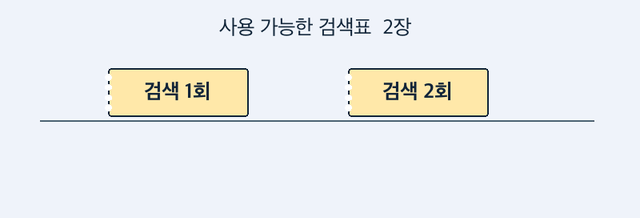

시도할 때마다 표 한 장을 씁니다. 최대 두 번이면 두 장을 모두 쓴 뒤에는 같은 실패가 돌아와도 세 번째 검색을 시작하지 않습니다.
<!-- /motion -->


### 셀 02 · 제공 셀 · 분기를 그래프에 연결하기

이미 실행한 route는 그대로 씁니다. search가 attempts를 올리는 줄과 rewrite 뒤에 다시 search로 돌아가는 엣지를 찾아보세요.

셀 01에서 나온 retry는 아직 최종 답이 아닙니다. 그래프는 rewrite로 이동한 뒤 search에 다시 들어갑니다. 다음 검색에서도 비었을 때 어떤 조건이 반복을 끝내는지 찾아보세요.

In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    question: str
    documents: list[str]
    answer: str
    attempts: int

def search(state: State) -> dict:
    if not state["question"].strip():
        raise ValueError("질문을 입력하세요.")
    documents = ["도서 대출 기간은 14일입니다."] if "대출" in state["question"] else []
    return {"documents": documents, "attempts": state["attempts"] + 1}

def rewrite(state: State) -> dict:
    return {"question": state["question"].replace("책", "대출")}

def answer(state: State) -> dict:
    return {"answer": " / ".join(state["documents"])}

def fallback(state: State) -> dict:
    return {"answer": "두 번 검색했지만 근거가 없습니다. 질문을 구체화해 주세요."}

def make_graph():
    builder = StateGraph(State)
    for name, node in [("search", search), ("rewrite", rewrite),
                       ("answer_node", answer), ("fallback", fallback)]:
        builder.add_node(name, node)
    builder.add_edge(START, "search")
    builder.add_conditional_edges("search", route,
        {"answer": "answer_node", "retry": "rewrite", "stop": "fallback"})
    builder.add_edge("rewrite", "search")
    builder.add_edge("answer_node", END)
    builder.add_edge("fallback", END)
    return builder.compile()

def run(question: str) -> State:
    initial: State = {"question": question, "documents": [], "answer": "", "attempts": 0}
    return make_graph().invoke(initial, config={"recursion_limit": 20})

print(search(after_search)['attempts'])

2


같은 상태에서 검색을 한 번 더 실행해 횟수가 2가 됐습니다. 이 셀의 함수 정의를 다음 셀에서 사용합니다.

### 셀 03 · 책을 대출로 바꿔 다시 찾기

질문 한 건의 마지막 상태에서 횟수와 답을 확인하세요.

In [3]:
result = run('책을 빌리는 기간?')
print(result['attempts'], result['answer'])

2 도서 대출 기간은 14일입니다.


두 번째 검색에서 ‘대출’이 들어 있는 질문으로 문장을 찾았습니다. 첫 번째 빈 결과만 보고 바로 끝냈다면 14일이라는 답까지 가지 못했을 것입니다.

### 과제 04 · 두 번 모두 빈 검색 멈추기

주차장 질문을 처리한 뒤 몇 번 검색했고 사용자에게 무엇을 안내하는지 출력하세요.

In [4]:
# 주차장 질문을 run에 전달하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>result = run(&#x27;주차장은?&#x27;)
print(result[&#x27;attempts&#x27;], result[&#x27;answer&#x27;])</code></pre>
<p>실행 결과</p><pre><code>2 두 번 검색했지만 근거가 없습니다. 질문을 구체화해 주세요.</code></pre>
<p>두 번 모두 문서가 비어 fallback으로 갑니다. attempts가 2일 때도 retry로 보내면 설계한 상한을 넘게 됩니다. 프레임워크의 recursion_limit은 이런 실수를 발견하는 별도 보호 장치입니다.</p>
</details>

## 돌아보기

검색 한 번에 바로 답하는 질문도 골라 보세요. 세 질문 모두 search 다음에 route를 거칩니다. 어떤 상태에서 다음 경로가 갈라졌나요?